# Department for Transport: GPs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df= pd.read_excel("dft_LSOA_GPs.xlsx", sheet_name='2019')
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (32844, 41)


,LSOA_code,Region,LA_Code,LA_Name,GP_pop,GPPTt,GPPT15n,GPPT30n,GPPT45n,GPPT60n,...,GPCar60pct,GPWalkt,GPWalk15n,GPWalk30n,GPWalk45n,GPWalk60n,GPWalk15pct,GPWalk30pct,GPWalk45pct,GPWalk60pct
0,E01000001,London,E09000001,City of London,863.214592,4.344932,1.240868,10.0,10.0,10.0,...,100.0,4.344932,1.113014,10.0,10.0,10.0,100.0,100.0,100.0,100.0
1,E01000002,London,E09000001,City of London,817.885979,8.806976,1.693976,10.0,10.0,10.0,...,100.0,8.806976,1.542169,10.0,10.0,10.0,100.0,100.0,100.0,100.0
2,E01000003,London,E09000001,City of London,805.075699,6.836316,2.487148,10.0,10.0,10.0,...,100.0,6.836316,2.487148,10.0,10.0,10.0,100.0,100.0,100.0,100.0
3,E01000005,London,E09000001,City of London,460.184021,8.653662,5.006424,10.0,10.0,10.0,...,100.0,8.653662,3.708779,10.0,10.0,10.0,100.0,100.0,100.0,100.0
4,E01000006,London,E09000002,Barking and Dagenham,601.834534,5.910147,8.425414,10.0,10.0,10.0,...,100.0,5.910147,8.425414,10.0,10.0,10.0,100.0,100.0,100.0,100.0


# Data Cleaning

In [2]:
#removes all leading and trailing whitespace from the column names
df.columns = df.columns.str.strip()

In [3]:
#check for missing values, duplicate rows/columns, and only display the unique rows
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Unique LSOAs:", df["LSOA_code"].nunique())

Missing values: 0
Duplicates: 0
Unique LSOAs: 32844


In [5]:
main_columns = [
    "LSOA_code",
    "GP_pop",
    "GPPTt",
    "GPCart",
    "GPCyct",
    "GPWalkt"
]

df[main_columns].isnull().sum()

LSOA_code    0
GP_pop       0
GPPTt        0
GPCart       0
GPCyct       0
GPWalkt      0
dtype: int64

In [11]:
numerical_columns = [
    "GP_pop",
    "GPPTt",
    "GPCart",
    "GPCyct",
    "GPWalkt"
]

df[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
GP_pop,32844.0,712.006363,142.226618,288.524719,623.263338,686.058746,782.025129,1542.486511
GPPTt,32844.0,13.188505,8.904366,1.643997,7.731602,11.532299,15.900017,116.476324
GPCart,32844.0,8.280075,2.261689,5.491891,6.830066,7.622786,8.913718,32.457807
GPCyct,32844.0,11.153521,5.679134,5.672156,7.845937,9.336994,11.955216,69.902716
GPWalkt,32844.0,18.228670,17.980743,1.643997,7.796268,12.272738,20.381602,120.000000


In [12]:
# Checking for impossible negative values
for col in numerical_columns:
    print(
        col,
        (df[col] < 0).sum()
    )

GP_pop 0
GPPTt 0
GPCart 0
GPCyct 0
GPWalkt 0


# Exploratory Data Analysis

## Travel-time accessibility variables.

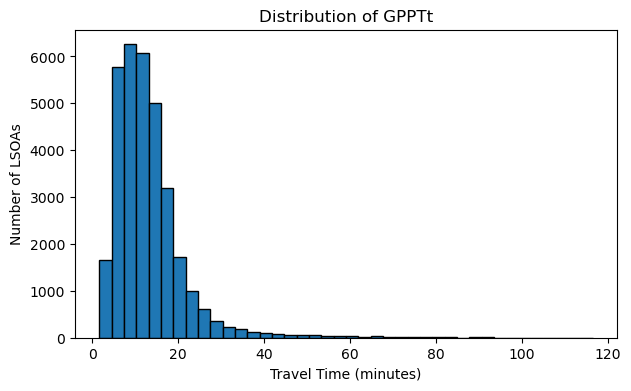

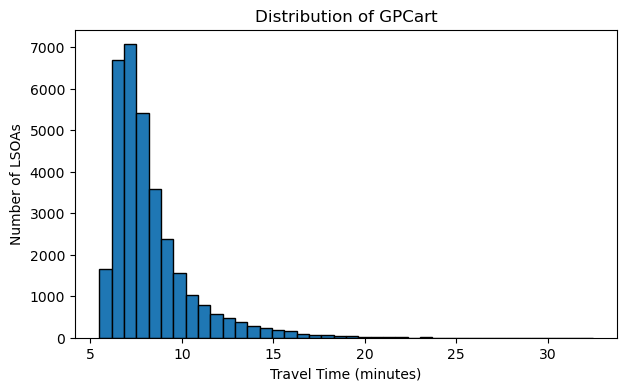

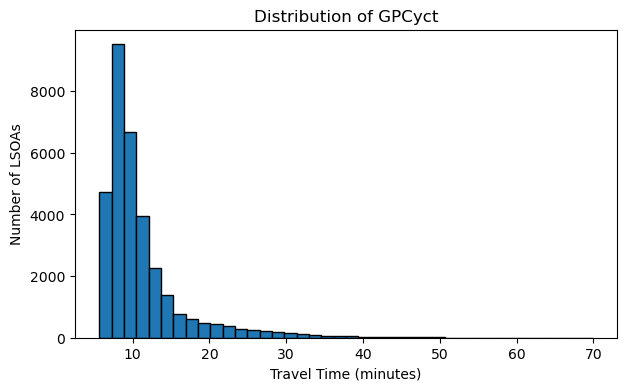

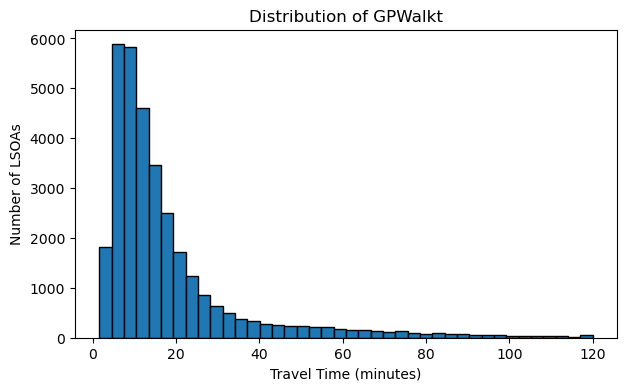

In [13]:
## Distribution of GP travel times
travel_time_columns = [
    "GPPTt",
    "GPCart",
    "GPCyct",
    "GPWalkt"
]
for col in travel_time_columns:

    plt.figure(figsize=(7, 4))

    plt.hist(
        df[col].dropna(),
        bins=40,
        edgecolor="black"
    )

    plt.xlabel("Travel Time (minutes)")
    plt.ylabel("Number of LSOAs")
    plt.title(f"Distribution of {col}")

    plt.show()

Car Access (GPCart): Fastest and most concentrated mode, peaking sharply around 6 to 8 minutes with almost all journeys under 15 minutes.

Cycling (GPCyct): Highly efficient local option, peaking tightly around 7 to 9 minutes and dropping off quickly after 15 minutes.

Public Transport (GPPTt): Moderate speeds, peaking around 8 to 12 minutes, but with a broader distribution extending up to 30+ minutes.

Walking (GPWalkt): Most widely dispersed, peaking around 5 to 10 minutes but displaying a long tail that stretches past 60 minutes for poorly connected areas.

Overall Pattern: All four modes show strong localized access to primary care, with cycling, walking and driving remaining substantially faster than public transport.

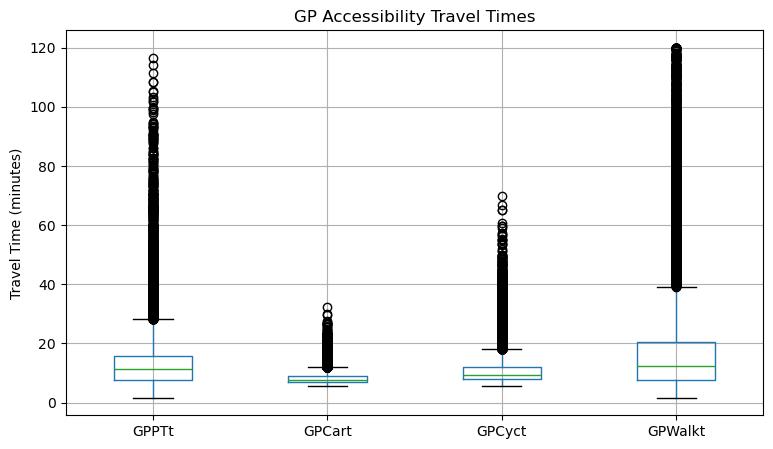

In [15]:
#Outlier detection using Boxplot
plt.figure(figsize=(9, 5))

df[
    ["GPPTt", "GPCart", "GPCyct", "GPWalkt"]
].boxplot()

plt.ylabel("Travel Time (minutes)")
plt.title("GP Accessibility Travel Times")

plt.show()

Outlier severity increases directly with mode reliance-cars maintain the tightest bound, while active walking and public transit display severe upper-tail vulnerability.

The dense outlier clusters for walking (GPWalkt) and public transport (GPPTt) reveal systemic coverage gaps, where residents in remote or poorly connected areas face extreme travel times (up to 2 hours) for primary care.

## Regional Comparison

In [16]:

region_gp = (
    df.groupby("Region")[
        ["GPPTt", "GPCart", "GPCyct", "GPWalkt"]
    ]
    .mean()
    .round(2)
)

region_gp

,GPPTt,GPCart,GPCyct,GPWalkt
Region,,,,
East,15.29,8.83,12.50,22.63
East Midlands,14.30,8.57,12.03,21.18
London,8.05,7.08,7.98,8.38
North East,12.96,8.29,11.37,18.23
North West,12.23,7.95,10.38,15.81
South East,14.42,8.65,11.86,20.25
South West,16.31,9.10,13.28,24.98
West Midlands,13.40,8.21,10.99,17.68
Yorkshire and The Humber,13.59,8.30,11.44,19.22


London shows the lowest average travel times across all transit types (~7.1 to 8.4 minutes), with minimal variance between walking, cycling, transit, and driving due to high service density.

Driving (GPCart) remains the fastest and most uniform mode nationwide, ranging narrowly from 7.08 minutes (London) to 9.10 minutes (South West).

Walking (GPWalkt) shows the highest regional disparity—ranging from 8.38 minutes in London to nearly 25 minutes in the South West, where low density makes pedestrian access impractical.

The South West records the highest mean travel times across every single transport mode (e.g., 16.31 minutes for transit, 24.98 minutes for walking).

## Public transport accessibility by Region

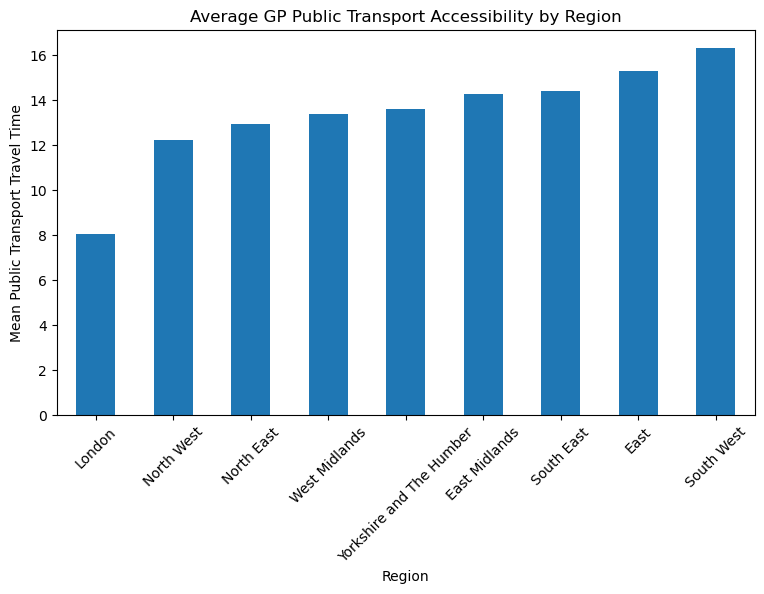

In [17]:
region_gp["GPPTt"].sort_values().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Mean Public Transport Travel Time")
plt.title("Average GP Public Transport Accessibility by Region")

plt.xticks(rotation=45)

plt.show()

London, North West and West Midlands being the most urbanised regions in England has easiest public transport accessibility while East and South West having more travel time to access public transport.

In [19]:
correlation_matrix = df[
    ["GPPTt", "GPCart", "GPCyct", "GPWalkt"]
].corr()

correlation_matrix

,GPPTt,GPCart,GPCyct,GPWalkt
GPPTt,1.000000,0.857243,0.860247,0.859879
GPCart,0.857243,1.000000,0.969113,0.956891
GPCyct,0.860247,0.969113,1.000000,0.992016
GPWalkt,0.859879,0.956891,0.992016,1.000000


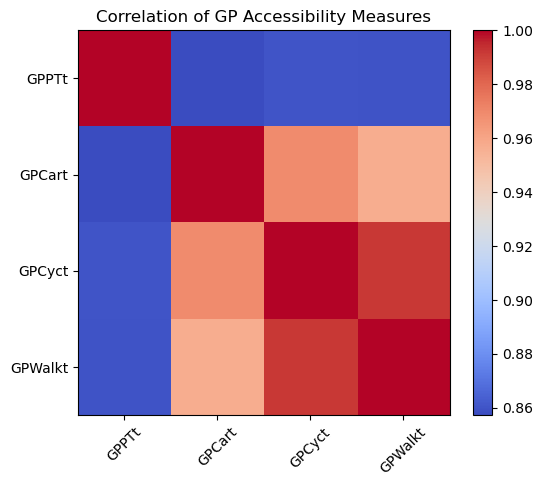

In [20]:
plt.figure(figsize=(6, 5))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

plt.title("Correlation of GP Accessibility Measures")

plt.show()

Strong Overall Collinearity: All transport modes show extremely high positive correlations (more than 0.85), meaning an area with long travel times by one mode generally experiences longer travel times across all other modes. Public transport (GPPTt) shows slightly lower correlations with the other modes, reflecting that bus and train availability depends heavily on transit schedules, route networks, and stops rather than pure geographic distance.

# Feature Engineering

In [23]:
# Public transport versus car accessibility gap
df["GP_PT_Car_Gap"] = (
    df["GPPTt"] -
    df["GPCart"]
)
df[ ["GPPTt", "GPCart", "GP_PT_Car_Gap"] ].describe()

,GPPTt,GPCart,GP_PT_Car_Gap
count,32844.000000,32844.000000,32844.000000
mean,13.188505,8.280075,4.908430
std,8.904366,2.261689,7.062229
min,1.643997,5.491891,-5.470824
25%,7.731602,6.830066,0.820293
50%,11.532299,7.622786,3.819913
75%,15.900017,8.913718,6.886174
max,116.476324,32.457807,95.557764


Large positive value shows that access to GP takes considerably longer to reach by public transport than by car. Value close to zero indicates public transport and car accessibility are relatively similar. While negative value represents public transport is faster than car.

In [25]:
#Relative Public Tranport disadvantage over Car travel. Proportional measure
df["GP_PT_Car_Ratio"] = (
    df["GPPTt"] / df["GPCart"]
)

In [27]:
gp_features = df[
    [
        "LSOA_code",
        "GP_pop",
        "GPPTt",
        "GPCart",
        "GPCyct",
        "GPWalkt",
        "GPPT30pct",
        "GP_PT_Car_Gap"
    ]
].copy()

gp_features.head()

,LSOA_code,GP_pop,GPPTt,GPCart,GPCyct,GPWalkt,GPPT30pct,GP_PT_Car_Gap
0,E01000001,863.214592,4.344932,6.695514,6.839098,4.344932,100.0,-2.350582
1,E01000002,817.885979,8.806976,7.411181,8.394807,8.806976,100.0,1.395795
2,E01000003,805.075699,6.836316,7.337050,7.504284,6.836316,100.0,-0.500734
3,E01000005,460.184021,8.653662,6.941841,8.015760,8.653662,100.0,1.711820
4,E01000006,601.834534,5.910147,6.329853,6.966888,5.910147,100.0,-0.419705


In [28]:
print(gp_features.shape)

(32844, 8)


The dataset was cleaned and transformed and then the selected features were then saved into a new dataset as shown below

In [29]:
gp_features.to_excel(
    "gp_accessibility_features.xlsx",
    index=False
)